## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 16.08.2024

Date of Last Modification: 17.08.2024

# 1. Setup

## 1.1 Libraries 

In [1]:
import torch
import os
import logging
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
from src.nichejepa.train import train
from src.nichejepa.eval import evaluation
from src.nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from src.nichejepa.utils.distributed import init_distributed
from src.nichejepa.utils.eval_utils import clustering_metrics, classification_metrics



## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [2]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('configs/cnd_gtb10_ep300.yaml',logger)

INFO:root:Loaded parameters from YAML file.


## 1.3 Create Train,Test dataset

In [3]:
train_dataset, test_dataset = prepare_dataset(params)

## 1.4 INIT distributed (it should change later)

In [4]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40316)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2.Model Training With just_cell and just_neighborhood as True

## 2.1 Train Model

In [31]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:[1,     0] loss: 0.534 masks: 286.0 20.0 [wd: 4.00e-02] [lr: 4.99e-05] [mem: 9.86e+03] (374.4 ms)
INFO:root:[1,     0] grad_stats: [8.49e-02 7.73e-02] (2.83e-04, 1.04e-01)
INFO:root:[1,    10] loss: 0.373 masks: 296.0 19.6 [wd: 4.01e-02] [lr: 4.87e-05] [mem: 1.10e+04] (242.9 ms)
INFO:root:[1,    10] grad_stats: [4.33e-03 4.51e-03] (1.50e-05, 5.46e-03)
INFO:root:[1,    20] loss: 0.342 masks: 296.7 19.8 [wd: 4.03e-02] [lr: 4.75e-05] [mem: 1.10e+04] (236.2 ms)
INFO:root:[1,    20] grad_stats: [1.27e-03 1.38e-03] (5.53e-06, 1.80e-03)
INFO:root:[1,    30] loss: 0.329 masks: 299.3 19.8 [wd: 4.06e-02] [lr: 4.63e-05] [mem: 1.14e+04] (234.9 ms)
INFO:root:[1,    30] grad_stats: [7.06e-04 7.29e-04] (3.88e-06, 9.54e-04)
INFO:root:[1,    40] loss: 0.322 masks: 298.9 19.9 [wd: 4.10e-02] [lr: 4.52e-05] [mem: 1.14e+04] (233.6 ms)
INFO:root:[1,    40] grad_stats: [7.75e-04 9.43e-04] (3.53e-06, 1.22e-03)
INFO:root:[1,    50] loss: 0.316 masks: 299.1 19.8 [wd: 4.15e-02] [lr: 4.40e-05] [mem: 1.1

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


INFO:root:avg. loss 0.283
INFO:root:Epoch 2
INFO:root:[2,     0] loss: 0.208 masks: 305.0 20.0 [wd: 4.40e-02] [lr: 4.01e-05] [mem: 1.17e+04] (269.6 ms)
INFO:root:[2,     0] grad_stats: [4.20e-04 4.69e-04] (1.53e-06, 5.91e-04)
INFO:root:[2,    10] loss: 0.206 masks: 302.5 20.0 [wd: 4.50e-02] [lr: 3.89e-05] [mem: 1.17e+04] (235.3 ms)
INFO:root:[2,    10] grad_stats: [6.84e-04 8.62e-04] (2.60e-06, 1.15e-03)
INFO:root:[2,    20] loss: 0.206 masks: 303.2 20.0 [wd: 4.62e-02] [lr: 3.77e-05] [mem: 1.17e+04] (234.9 ms)
INFO:root:[2,    20] grad_stats: [3.07e-04 3.61e-04] (1.33e-06, 4.53e-04)
INFO:root:[2,    30] loss: 0.205 masks: 302.9 19.9 [wd: 4.74e-02] [lr: 3.65e-05] [mem: 1.17e+04] (233.5 ms)
INFO:root:[2,    30] grad_stats: [4.33e-04 5.81e-04] (1.84e-06, 7.40e-04)
INFO:root:[2,    40] loss: 0.204 masks: 302.2 19.9 [wd: 4.87e-02] [lr: 3.54e-05] [mem: 1.17e+04] (232.8 ms)
INFO:root:[2,    40] grad_stats: [8.57e-04 1.12e-03] (3.47e-06, 1.53e-03)
INFO:root:[2,    50] loss: 0.202 masks: 301.5 

# 3. Analysis With just_cell and just_neighborhood as True

## 3.1 Cell Type Average

In [32]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root:loaded pretrained encoder from epoch 15 wit

83it [00:10,  8.06it/s]
21it [00:03,  6.56it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/cell_embedding_average.h5ad


### 3.1.1 Feature Analysis

In [33]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.9999997 , 0.99866295, 0.99819136, ..., 0.99804395, 0.99844337,
        0.99844307],
       [0.99866295, 0.9999994 , 0.99832225, ..., 0.9981718 , 0.9986068 ,
        0.99841213],
       [0.99819136, 0.99832225, 0.9999999 , ..., 0.9982644 , 0.99785614,
        0.9983127 ],
       ...,
       [0.99804395, 0.9981718 , 0.9982644 , ..., 1.0000002 , 0.9977312 ,
        0.9982198 ],
       [0.99844337, 0.9986068 , 0.99785614, ..., 0.9977312 , 1.        ,
        0.9982924 ],
       [0.99844307, 0.99841213, 0.9983127 , ..., 0.9982198 , 0.9982924 ,
        1.        ]], dtype=float32)

### 3.1.2 Umap

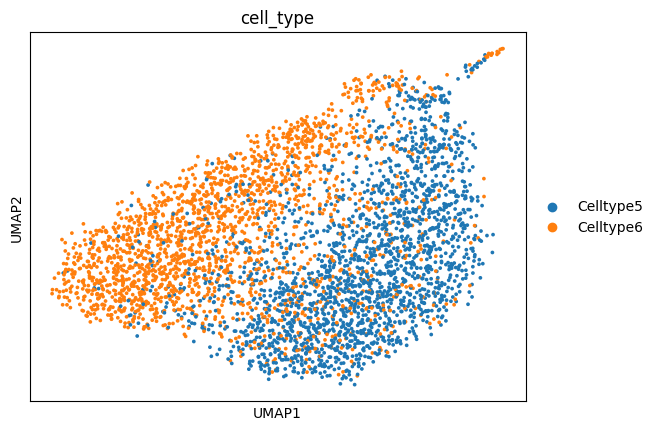

In [34]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.1.3 Logistic regression

In [35]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.93
Test F1 Score: 0.93
Train Accuracy: 0.95
Train F1 Score: 0.95


{'test_accuracy': 0.927536231884058,
 'test_f1': 0.9275320039289542,
 'train_accuracy': 0.9471458773784355,
 'train_f1': 0.9471453948122985}

### 3.1.4 KNeighborsClassifier

In [36]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.89
Train F1 Score: 0.89


{'test_accuracy': 0.857487922705314,
 'test_f1': 0.8572047425532444,
 'train_accuracy': 0.8888553307157958,
 'train_f1': 0.88857370562205}

### 3.1.5 nmi&ari

In [37]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.0003756403817893183
ARI (Adjusted Rand Index): 0.0005878291784482887


{'nmi': 0.0003756403817893183, 'ari': 0.0005878291784482887}

## 3.2 Cell Type CLS

In [38]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
82it [00:10,  9.43it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:10,  7.92it/s]
21it [00:03,  6.83it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/cell_embedding_cls.h5ad


### 3.2.1 Feature Analysis

In [39]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.99999994, 0.9999808 , 0.9998748 , ..., 0.99988616, 0.999861  ,
        0.9999585 ],
       [0.9999808 , 1.        , 0.99987984, ..., 0.99989164, 0.9998604 ,
        0.9999583 ],
       [0.9998748 , 0.99987984, 0.99999976, ..., 0.99998724, 0.9995372 ,
        0.9999579 ],
       ...,
       [0.99988616, 0.99989164, 0.99998724, ..., 1.0000001 , 0.9995643 ,
        0.9999639 ],
       [0.999861  , 0.9998604 , 0.9995372 , ..., 0.9995643 , 0.9999999 ,
        0.99972785],
       [0.9999585 , 0.9999583 , 0.9999579 , ..., 0.9999639 , 0.99972785,
        1.        ]], dtype=float32)

### 3.2.2 Umap

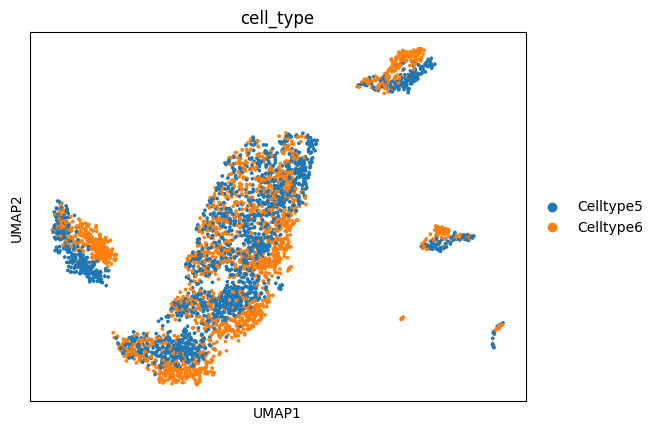

In [40]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [42]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.85
Train F1 Score: 0.85


{'test_accuracy': 0.857487922705314,
 'test_f1': 0.8572631284301765,
 'train_accuracy': 0.8544246451223195,
 'train_f1': 0.8540831529817822}

### 3.2.4 KNeighborsClassifier

In [43]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.82
Test F1 Score: 0.82
Train Accuracy: 0.89
Train F1 Score: 0.89


{'test_accuracy': 0.8236714975845411,
 'test_f1': 0.8236714975845411,
 'train_accuracy': 0.8897614013893084,
 'train_f1': 0.8897726513297022}

### 3.2.5 nmi&ari

In [44]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.00038850306523244884
ARI (Adjusted Rand Index): 0.0006114855745187499


{'nmi': 0.00038850306523244884, 'ari': 0.0006114855745187499}

## 3.3 Cell Type weighted_average

In [45]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
82it [00:10,  9.41it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:10,  7.94it/s]
21it [00:03,  6.27it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/cell_embedding_weighted_average.h5ad


### 3.3.1 Feature Analysis

In [46]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.99925184, 0.99439615, ..., 0.99277526, 0.9951968 ,
        0.9977369 ],
       [0.99925184, 0.9999997 , 0.99578303, ..., 0.9943572 , 0.99391127,
        0.99849355],
       [0.99439615, 0.99578303, 0.9999997 , ..., 0.99938667, 0.98152554,
        0.99855447],
       ...,
       [0.99277526, 0.9943572 , 0.99938667, ..., 0.9999999 , 0.9784999 ,
        0.9978026 ],
       [0.9951968 , 0.99391127, 0.98152554, ..., 0.9784999 , 1.        ,
        0.988569  ],
       [0.9977369 , 0.99849355, 0.99855447, ..., 0.9978026 , 0.988569  ,
        1.0000002 ]], dtype=float32)

### 3.3.2 Umap

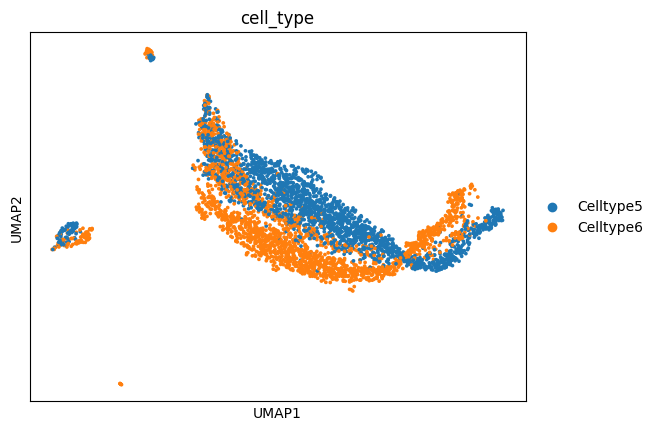

In [47]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [48]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.91
Test F1 Score: 0.91
Train Accuracy: 0.92
Train F1 Score: 0.92


{'test_accuracy': 0.9057971014492754,
 'test_f1': 0.9057674156619169,
 'train_accuracy': 0.9232860163092721,
 'train_f1': 0.9232588939863142}

### 3.3.4 KNN

In [49]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.91
Train F1 Score: 0.91


{'test_accuracy': 0.8599033816425121,
 'test_f1': 0.8596823974398344,
 'train_accuracy': 0.9121111446692842,
 'train_f1': 0.9120102100091283}

### 3.3.5 nmi&ari

In [50]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.00045577175845401406
ARI (Adjusted Rand Index): 0.0007033705466000319


{'nmi': 0.00045577175845401406, 'ari': 0.0007033705466000319}

## 3.4 Niche Type Average

In [51]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
82it [00:09,  9.42it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:10,  8.21it/s]
21it [00:03,  6.36it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/niche_embedding_average.h5ad


### 3.4.1 Feature Analysis

In [52]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.9999999 , 0.9998373 , 0.99976325, ..., 0.999768  , 0.9995888 ,
        0.99984705],
       [0.9998373 , 1.        , 0.9997653 , ..., 0.9997717 , 0.9996085 ,
        0.9998553 ],
       [0.99976325, 0.9997653 , 1.0000002 , ..., 0.9999603 , 0.99927163,
        0.9999    ],
       ...,
       [0.999768  , 0.9997717 , 0.9999603 , ..., 1.        , 0.9992683 ,
        0.9998968 ],
       [0.9995888 , 0.9996085 , 0.99927163, ..., 0.9992683 , 1.        ,
        0.9994906 ],
       [0.99984705, 0.9998553 , 0.9999    , ..., 0.9998968 , 0.9994906 ,
        0.9999999 ]], dtype=float32)

### 3.4.2 Umap

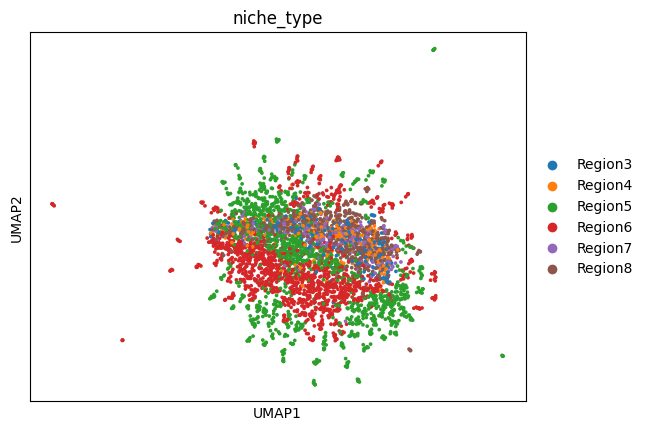

In [53]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [54]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.75
Test F1 Score: 0.68
Train Accuracy: 0.72
Train F1 Score: 0.65


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.7524154589371981,
 'test_f1': 0.6831025320345385,
 'train_accuracy': 0.7245545152521897,
 'train_f1': 0.6455654927483623}

### 3.4.4 KNN

In [55]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.80
Test F1 Score: 0.79
Train Accuracy: 0.88
Train F1 Score: 0.88


{'test_accuracy': 0.7958937198067633,
 'test_f1': 0.7868460575550067,
 'train_accuracy': 0.8825128360012081,
 'train_f1': 0.8780350867029222}

### 3.4.5 nmi&ari

In [56]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.004014442925447062
ARI (Adjusted Rand Index): 0.00020161129221124856


{'nmi': 0.004014442925447062, 'ari': 0.00020161129221124856}

## 3.5 Niche Type CLS

In [57]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
82it [00:10,  9.41it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:10,  8.03it/s]
21it [00:03,  6.43it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/niche_embedding_cls.h5ad


### 3.5.1 Feature Analysis

In [58]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.99999994, 0.9999808 , 0.9998748 , ..., 0.99988616, 0.999861  ,
        0.9999585 ],
       [0.9999808 , 1.        , 0.99987984, ..., 0.99989164, 0.9998604 ,
        0.9999583 ],
       [0.9998748 , 0.99987984, 0.99999976, ..., 0.99998724, 0.9995372 ,
        0.9999579 ],
       ...,
       [0.99988616, 0.99989164, 0.99998724, ..., 1.0000001 , 0.9995643 ,
        0.9999639 ],
       [0.999861  , 0.9998604 , 0.9995372 , ..., 0.9995643 , 0.9999999 ,
        0.99972785],
       [0.9999585 , 0.9999583 , 0.9999579 , ..., 0.9999639 , 0.99972785,
        1.        ]], dtype=float32)

### 3.5.2 Umap

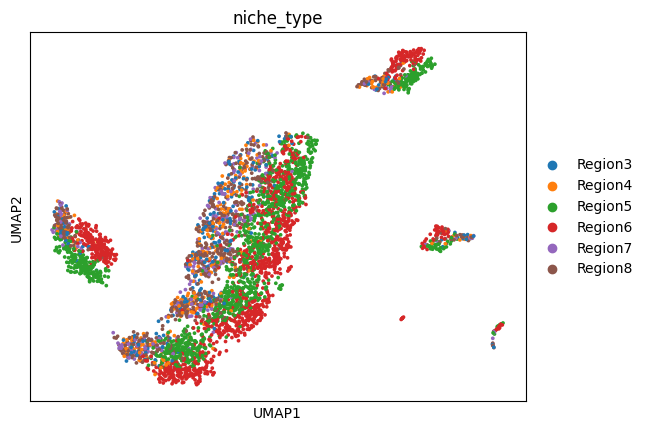

In [59]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [60]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.75
Test F1 Score: 0.68
Train Accuracy: 0.72
Train F1 Score: 0.65


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.7524154589371981,
 'test_f1': 0.6837979587527074,
 'train_accuracy': 0.7236484445786772,
 'train_f1': 0.6475087820416203}

### 3.5.4 KNN

In [61]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.73
Test F1 Score: 0.72
Train Accuracy: 0.82
Train F1 Score: 0.81


{'test_accuracy': 0.7306763285024155,
 'test_f1': 0.7203368575091529,
 'train_accuracy': 0.8178797946239806,
 'train_f1': 0.8078975617706841}

### 3.5.5 nmi&ari

In [62]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.004197703116685896
ARI (Adjusted Rand Index): 0.0005348708267521743


{'nmi': 0.004197703116685896, 'ari': 0.0005348708267521743}

## 3.6 Niche Type weighted_average

In [63]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
82it [00:09,  9.40it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:10,  8.11it/s]
21it [00:03,  6.55it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/niche_embedding_weighted_average.h5ad


### 3.6.1 Feature Analysis

In [64]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.99925184, 0.99439615, ..., 0.99277526, 0.9951968 ,
        0.9977369 ],
       [0.99925184, 0.9999997 , 0.99578303, ..., 0.9943572 , 0.99391127,
        0.99849355],
       [0.99439615, 0.99578303, 0.9999997 , ..., 0.99938667, 0.98152554,
        0.99855447],
       ...,
       [0.99277526, 0.9943572 , 0.99938667, ..., 0.9999999 , 0.9784999 ,
        0.9978026 ],
       [0.9951968 , 0.99391127, 0.98152554, ..., 0.9784999 , 1.        ,
        0.988569  ],
       [0.9977369 , 0.99849355, 0.99855447, ..., 0.9978026 , 0.988569  ,
        1.0000002 ]], dtype=float32)

### 3.6.2 Umap

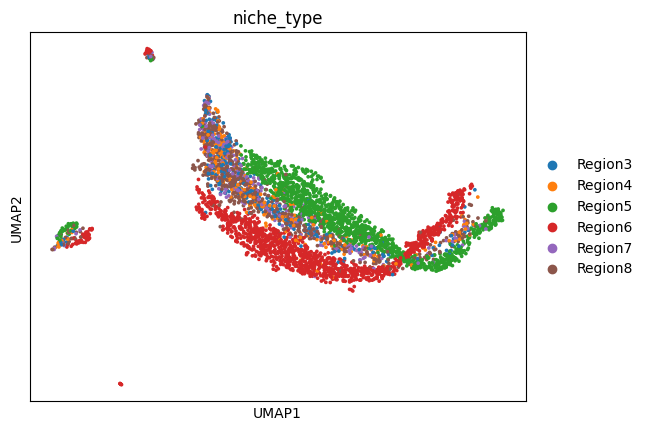

In [65]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [66]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.83
Test F1 Score: 0.78
Train Accuracy: 0.82
Train F1 Score: 0.78


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'test_accuracy': 0.8285024154589372,
 'test_f1': 0.783192649269265,
 'train_accuracy': 0.8154636061612806,
 'train_f1': 0.7783269998694997}

### 3.6.4 KNN

In [67]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.77
Test F1 Score: 0.74
Train Accuracy: 0.84
Train F1 Score: 0.82


{'test_accuracy': 0.7717391304347826,
 'test_f1': 0.7448903638933854,
 'train_accuracy': 0.8381153729990939,
 'train_f1': 0.8220843102683568}

### 3.6.5 nmi&ari

In [68]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.0709945602029625
ARI (Adjusted Rand Index): 0.051457090539270466


{'nmi': 0.0709945602029625, 'ari': 0.051457090539270466}

## 3.7 Retrieve Gene

In [69]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
82it [00:10,  9.41it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:10,  7.99it/s]
21it [00:03,  6.45it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_just_neighborhood_subset_Celltype5_Celltype6/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 3.7.1 Feature Analysis

In [70]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 1.        , 0.        , ..., 0.        , 0.99985147,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.99985147, 0.        , ..., 0.        , 1.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], dtype=float32)

### 3.7.2 Umap

In [71]:
adata = adata[adata.obs['gene_count']!=0]

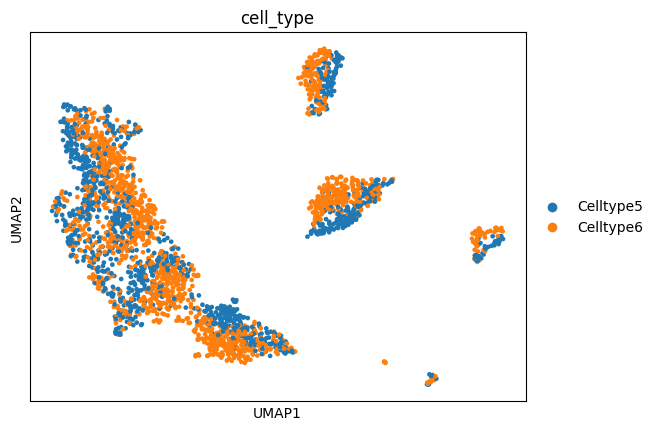

In [72]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

# 4.Model Training With just_cell as True

## 4.1 Train Model

In [5]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
train(params, train_dataset, test_dataset)

INFO:root:Initialized (rank/world-size) 0/1
INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)
INFO:root

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:Initializing learning rate scheduler: WarmupCosineSchedule
INFO:root:Initializing weight decay scheduler: CosineWDSchedule
INFO:root:Initializing automatic mixed precision training scaler: GradScaler
INFO:root:Epoch 1


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:[1,     0] loss: 0.531 masks: 285.0 19.0 [wd: 4.00e-02] [lr: 4.99e-05] [mem: 9.40e+03] (861.1 ms)
INFO:root:[1,     0] grad_stats: [1.40e-01 1.28e-01] (3.43e-04, 1.70e-01)
INFO:root:[1,    10] loss: 0.310 masks: 285.0 19.3 [wd: 4.01e-02] [lr: 4.87e-05] [mem: 9.83e+03] (194.3 ms)
INFO:root:[1,    10] grad_stats: [5.10e-03 5.26e-03] (1.22e-05, 6.47e-03)
INFO:root:[1,    20] loss: 0.267 masks: 285.0 19.5 [wd: 4.03e-02] [lr: 4.75e-05] [mem: 9.83e+03] (162.6 ms)
INFO:root:[1,    20] grad_stats: [1.55e-03 1.59e-03] (3.99e-06, 1.96e-03)
INFO:root:[1,    30] loss: 0.247 masks: 285.0 19.5 [wd: 4.06e-02] [lr: 4.63e-05] [mem: 9.83e+03] (150.7 ms)
INFO:root:[1,    30] grad_stats: [7.66e-04 7.96e-04] (2.28e-06, 1.03e-03)
INFO:root:[1,    40] loss: 0.236 masks: 285.0 19.5 [wd: 4.10e-02] [lr: 4.52e-05] [mem: 9.83e+03] (144.9 ms)
INFO:root:[1,    40] grad_stats: [4.39e-04 4.61e-04] (1.59e-06, 5.75e-04)
INFO:root:[1,    50] loss: 0.229 masks: 285.0 19.6 [wd: 4.15e-02] [lr: 4.40e-05] [mem: 9.8

# 5. Analysis With just_cell as True

## 5.1 Cell Type Average

In [6]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


83it [00:04, 18.70it/s]
21it [00:01, 19.72it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/cell_embedding_average.h5ad


### 5.1.1 Feature Analysis

In [7]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.99869585, 0.9984295 , ..., 0.99837613, 0.9988372 ,
        0.9986793 ],
       [0.99869585, 1.0000001 , 0.998604  , ..., 0.9984662 , 0.998754  ,
        0.9987416 ],
       [0.9984295 , 0.998604  , 1.0000001 , ..., 0.9984325 , 0.99864113,
        0.9986087 ],
       ...,
       [0.99837613, 0.9984662 , 0.9984325 , ..., 0.9999998 , 0.9983847 ,
        0.9987024 ],
       [0.9988372 , 0.998754  , 0.99864113, ..., 0.9983847 , 1.0000002 ,
        0.9988562 ],
       [0.9986793 , 0.9987416 , 0.9986087 , ..., 0.9987024 , 0.9988562 ,
        1.0000002 ]], dtype=float32)

### 5.1.2 Umap

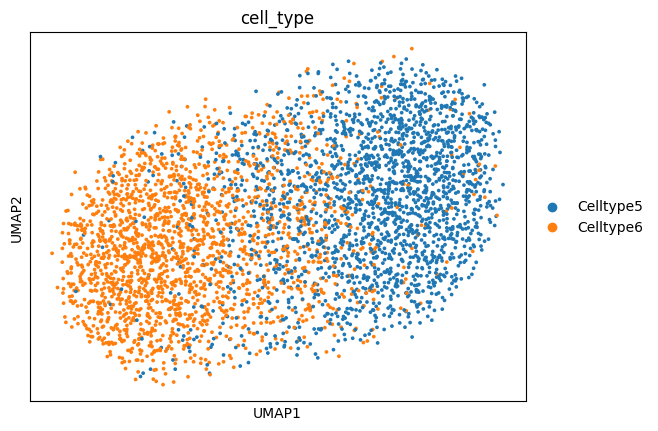

In [8]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.1.3 Logistic regression

In [9]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.93
Test F1 Score: 0.93
Train Accuracy: 0.95
Train F1 Score: 0.95


{'test_accuracy': 0.928743961352657,
 'test_f1': 0.9287411550761103,
 'train_accuracy': 0.9492600422832981,
 'train_f1': 0.9492560762231176}

### 5.1.4 KNN

In [10]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.90
Train F1 Score: 0.90


{'test_accuracy': 0.857487922705314,
 'test_f1': 0.8573381307384287,
 'train_accuracy': 0.9036544850498339,
 'train_f1': 0.9035798853479755}

### 5.1.5 nmi&ari

In [12]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 8.07386782535153e-06
ARI (Adjusted Rand Index): -0.0002523721756918879


{'nmi': 8.07386782535153e-06, 'ari': -0.0002523721756918879}

## 5.2 Cell Type CLS

In [13]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
80it [00:03, 51.15it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:03, 24.11it/s]
21it [00:01, 19.84it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/cell_embedding_cls.h5ad


### 5.2.1 Feature Analysis

In [14]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.9999036 , 0.9998617 , ..., 0.9998206 , 0.99990845,
        0.99989396],
       [0.9999036 , 1.0000002 , 0.99990094, ..., 0.9998615 , 0.9999042 ,
        0.9999156 ],
       [0.9998617 , 0.99990094, 1.0000002 , ..., 0.99990416, 0.9998541 ,
        0.99990296],
       ...,
       [0.9998206 , 0.9998615 , 0.99990416, ..., 0.9999995 , 0.9997965 ,
        0.9998958 ],
       [0.99990845, 0.9999042 , 0.9998541 , ..., 0.9997965 , 1.0000001 ,
        0.9998969 ],
       [0.99989396, 0.9999156 , 0.99990296, ..., 0.9998958 , 0.9998969 ,
        1.0000001 ]], dtype=float32)

### 5.2.2 Umap

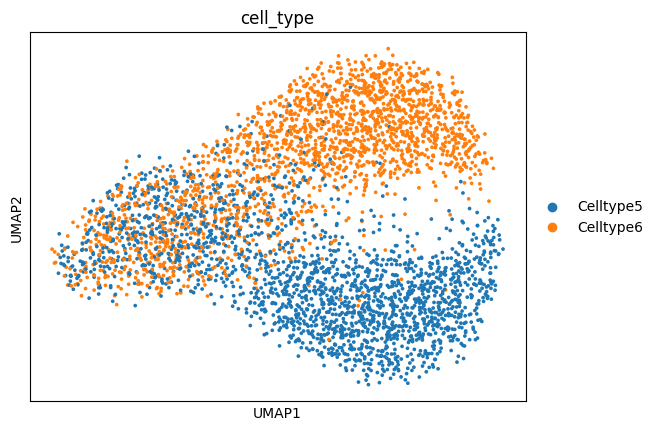

In [15]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 5.2.3 Logistic regression

In [16]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.89
Test F1 Score: 0.89
Train Accuracy: 0.89
Train F1 Score: 0.89


{'test_accuracy': 0.8900966183574879,
 'test_f1': 0.8900974199178324,
 'train_accuracy': 0.8888553307157958,
 'train_f1': 0.8888659225391436}

### 5.2.4 KNN

In [17]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.91
Train F1 Score: 0.91


{'test_accuracy': 0.855072463768116,
 'test_f1': 0.8550267813295874,
 'train_accuracy': 0.9069767441860465,
 'train_f1': 0.9069633046028687}

### 5.2.5 nmi&ari

In [18]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.0003000293354350344
ARI (Adjusted Rand Index): 0.00034297780153013676


{'nmi': 0.0003000293354350344, 'ari': 0.00034297780153013676}

## 5.3 Cell Type weighted_average

In [19]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
77it [00:03, 46.88it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:03, 23.45it/s]
21it [00:01, 17.40it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/cell_embedding_weighted_average.h5ad


### 5.3.1 Feature Analysis

In [20]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[1.        , 0.9984319 , 0.9979744 , ..., 0.9979354 , 0.9983828 ,
        0.998361  ],
       [0.9984319 , 0.99999994, 0.99795145, ..., 0.99803805, 0.9983659 ,
        0.99845946],
       [0.9979744 , 0.99795145, 0.99999976, ..., 0.99788135, 0.9980043 ,
        0.9980298 ],
       ...,
       [0.9979354 , 0.99803805, 0.99788135, ..., 1.0000001 , 0.9978068 ,
        0.998122  ],
       [0.9983828 , 0.9983659 , 0.9980043 , ..., 0.9978068 , 1.0000001 ,
        0.99840164],
       [0.998361  , 0.99845946, 0.9980298 , ..., 0.998122  , 0.99840164,
        0.99999976]], dtype=float32)

### 5.3.2 Umap

In [26]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

 Plot the UMAP
sc.pl.umap(adata, color='cell_type')

,split,label_name,retrieve_label,retrieve_position_emb,retrieve_emb_from_layer,cell_type,gene_count
0,train,cell_type,retrieve_cell,False,3,Celltype5,-1
1,train,cell_type,retrieve_cell,False,3,Celltype5,-1
2,train,cell_type,retrieve_cell,False,3,Celltype6,-1
3,train,cell_type,retrieve_cell,False,3,Celltype6,-1
4,train,cell_type,retrieve_cell,False,3,Celltype5,-1
...,...,...,...,...,...,...,...
4134,test,cell_type,retrieve_cell,False,3,Celltype5,-1
4135,test,cell_type,retrieve_cell,False,3,Celltype5,-1
4136,test,cell_type,retrieve_cell,False,3,Celltype5,-1
4137,test,cell_type,retrieve_cell,False,3,Celltype5,-1


### 5.3.3 Logistic regression

In [22]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.94
Test F1 Score: 0.94
Train Accuracy: 0.97
Train F1 Score: 0.97


{'test_accuracy': 0.9384057971014492,
 'test_f1': 0.9384062463118505,
 'train_accuracy': 0.9685895499848988,
 'train_f1': 0.9685933573705561}

### 5.3.4 KNN

In [23]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.86
Test F1 Score: 0.86
Train Accuracy: 0.91
Train F1 Score: 0.91


{'test_accuracy': 0.8623188405797102,
 'test_f1': 0.8622143515623095,
 'train_accuracy': 0.9127151917849592,
 'train_f1': 0.9127055471613401}

### 5.3.5 nmi&ari

In [24]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.46226397533884916
ARI (Adjusted Rand Index): 0.4238016617698564


{'nmi': 0.46226397533884916, 'ari': 0.4238016617698564}

## 5.4 Retrieve Gene

In [27]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = True
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = False
adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 768, padding_idx=0)
  (seg_embed): Embedding(3, 768, padding_idx=0)
  (blocks): ModuleList(
    (0-3): 4 x Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=3072, out_features=768, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
)


/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 18 worker processes in total. Our suggested max number of worker in current system is 12, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>
['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']
INFO:root:loaded pretrained encoder from epoch 15 with msg: <All keys matched successfully>


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
77it [00:03, 49.64it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
83it [00:03, 25.24it/s]
21it [00:01, 18.88it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/Simulated_data_pred_depth_3_pred_emb_dim_768_enc_depth_4_n_targets_4_n_contexts_1_target_mask_size_19_context_mask_size_361_num_epochs_15_just_cell_subset_Celltype5_Celltype6/extracted_features/gene_embedding_gene_id_332_average.h5ad


### 5.4.1 Feature Analysis

In [28]:
similarity_matrix = cosine_similarity(adata.obsm['jepa_emb'])
similarity_matrix

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 1.       , 0.       , ..., 0.       , 0.9998965,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.9998965, 0.       , ..., 0.       , 0.9999997,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ]], dtype=float32)

In [29]:
adata = adata[adata.obs['gene_count']!=0]

### 5.4.2 Umap

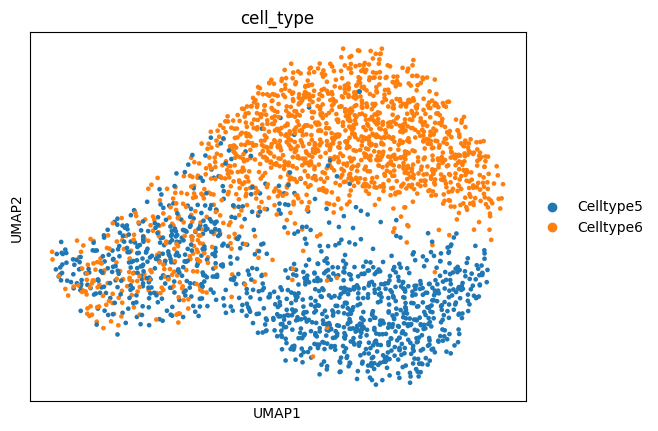

In [30]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')